In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [ ]:
!git clone https://github.com/jsenkins/PRM-guided-Best-of-N-search.git

Cloning into 'cs5326-pa3-starter'...
remote: Enumerating objects: 94, done.
remote: Counting objects: 100% (94/94), done.
remote: Compressing objects: 100% (52/52), done.
remote: Total 94 (delta 54), reused 77 (delta 37), pack-reused 0 (from 0)
Receiving objects: 100% (94/94), 47.44 KiB | 1.44 MiB/s, done.
Resolving deltas: 100% (54/54), done.


In [ ]:
%cd /kaggle/working/RM-guided-Best-of-N-search

/kaggle/working/cs5326-pa3-starter


In [11]:
#!ls

data		    pyproject.toml	requirements.txt       tests
make_submission.sh  README.md		src
outputs		    REPORT_TEMPLATE.md	submission_adapter.py


In [2]:
###!cd /kaggle/working && \
 #git rm --cached cs5326-pa3-starter && \
# rm -rf cs5326-pa3-starter/.git && \
 #git add . && \
 #git status --short | head -30

In [5]:
!pip install -q -U bitsandbytes

# problem 1 step structured generation and baseline decoders

### first smoke test 

In [8]:
!python tests/test_public_adapter_smoke.py

Running 20 public adapter smoke tests...
  [PASS] test_format_step_prompt
  [PASS] test_parse_steps_plain
  [PASS] test_parse_steps_markdown_decorated
  [PASS] test_extract_answer_required_behaviors
  [PASS] test_extract_answer_resilience
  [PASS] test_compute_majority_vote
  [PASS] test_run_greedy
  [PASS] test_run_self_consistency
  [FAIL] test_build_prm_judge_prompt_structure: Implement build_prm_judge_prompt in src/prm_judge.py
  [FAIL] test_parse_judge_decision: Implement parse_judge_decision in src/prm_judge.py
  [FAIL] test_score_path: Implement score_path in src/prm_judge.py
  [FAIL] test_aggregate_path_score: Implement aggregate_path_score in src/search.py
  [FAIL] test_select_best_path_clear_winner: Implement select_best_path in src/search.py
  [FAIL] test_select_best_path_tie_broken_by_majority: Implement select_best_path in src/search.py
  [FAIL] test_select_best_path_answer_none_exclusion: Implement select_best_path in src/search.py
  [FAIL] test_select_best_path_all_answe

testing

In [5]:
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer

gen_id = "Qwen/Qwen2.5-1.5B-Instruct"
gen_tok = AutoTokenizer.from_pretrained(gen_id)
if gen_tok.pad_token_id is None:
    gen_tok.pad_token_id = gen_tok.eos_token_id
gen_model = AutoModelForCausalLM.from_pretrained(
    gen_id, dtype=torch.float16, device_map={"": 0})

from src.utils import make_hf_generate_fn
gen_fn = make_hf_generate_fn(gen_model, gen_tok)

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

#### test 2 

In [ ]:

import importlib, src.generation
importlib.reload(src.generation)
from src.generation import run_greedy, format_step_prompt

question = "James decides to run 3 sprints 3 times a week.  He runs 60 meters each sprint.  How many total meters does he run a week?"
print(format_step_prompt(question))
print("=" * 40)
sample = run_greedy(question=question, generate_fn=gen_fn)
print(sample["completion"])
print(sample["answer"], sample["steps"])

Question: James decides to run 3 sprints 3 times a week.  He runs 60 meters each sprint.  How many total meters does he run a week?

Give me the solution to the math question. Show all the numbered steps short explanation and provide a final answer as an integer only.
Follow the Format below 
Step 1: one short plain sentence with one calculation written like 1 * 5 = 5.
Step 2: next short sentence with one calculation.
Step 3: Continue with the next step and state the current values
(continue, one step per line)
Final Answer: <integer>

Do not deviate from the following rules:Use plain text only. No markdown, no LaTeX, no \[ \], no \boxed{}, no brackets.
no units in the final answer.
Every line before the last starts with 'Step k:'. No concluding sentence.
write nothing after the last line that is the Final Answer line
The last line must be only be 'Final Answer: number' replace the number placeholder with the actual answer value only
Step 1: Calculate the distance for one set of three 

In [46]:
import json
from src.utils import set_seed_for_problem
from src.generation import run_greedy

problems = [json.loads(l) for l in open("data/gsm8k_test_50.jsonl")]
greedy = []
for i, p in enumerate(problems):
    set_seed_for_problem(i)
    greedy.append(run_greedy(question=p["question"], generate_fn=gen_fn))

none_idx = [i for i, r in enumerate(greedy) if r["answer"] is None]
correct = sum(r["answer"] == p["ground_truth_answer"] for r, p in zip(greedy, problems))
print("format failures:", len(none_idx), none_idx)
print("accuracy:", correct, "/ 50")
print("mean steps:", sum(len(r["steps"]) for r in greedy) / 50)

format failures: 5 [20, 30, 33, 36, 38]
accuracy: 31 / 50
mean steps: 4.18


# problem 2 PRM Verifier

#### second smoke test 

In [25]:
!python tests/test_public_adapter_smoke.py

Running 20 public adapter smoke tests...
  [PASS] test_format_step_prompt
  [PASS] test_parse_steps_plain
  [PASS] test_parse_steps_markdown_decorated
  [PASS] test_extract_answer_required_behaviors
  [PASS] test_extract_answer_resilience
  [PASS] test_compute_majority_vote
  [PASS] test_run_greedy
  [PASS] test_run_self_consistency
  [PASS] test_build_prm_judge_prompt_structure
  [PASS] test_parse_judge_decision
  [PASS] test_score_path
  [PASS] test_aggregate_path_score
  [PASS] test_select_best_path_clear_winner
  [PASS] test_select_best_path_tie_broken_by_majority
  [PASS] test_select_best_path_answer_none_exclusion
  [PASS] test_select_best_path_all_answers_none
  [PASS] test_run_prm_best_of_n_standalone
  [PASS] test_run_prm_best_of_n_with_shared_candidates
  [PASS] test_run_compute_matched_self_consistency
  [PASS] test_scaling_curve_consistency
Test Summary: 20 passed, 0 failed.
ALL TESTS PASSED SUCCESSFULLY!


In [ ]:
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig

judge_id = "Qwen/Qwen2.5-7B-Instruct"
judge_tok = AutoTokenizer.from_pretrained(judge_id)
if judge_tok.pad_token_id is None:
    judge_tok.pad_token_id = judge_tok.eos_token_id

bnb = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                         bnb_4bit_compute_dtype=torch.float16,
                         bnb_4bit_use_double_quant=True)
judge_dev = {"": 1} if torch.cuda.device_count() > 1 else {"": 0}
judge_model = AutoModelForCausalLM.from_pretrained(
    judge_id, quantization_config=bnb, device_map=judge_dev)

from src.utils import make_hf_judge_fn
judge_fn = make_hf_judge_fn(judge_model, judge_tok)
print("judge loaded on", judge_model.device)

In [9]:
import json, os
from transformers import set_seed
from submission_adapter import (
    run_greedy, run_self_consistency, run_prm_best_of_n,
    run_compute_matched_self_consistency, select_best_path,
)
from src.utils import make_hf_generate_fn, make_hf_judge_fn

gen_fn   = make_hf_generate_fn(gen_model, gen_tok)
judge_fn = make_hf_judge_fn(judge_model, judge_tok)

problems = [json.loads(l) for l in open("data/gsm8k_test_50.jsonl")]
OUT = "outputs/per_problem.jsonl"
os.makedirs("outputs", exist_ok=True)
done = {json.loads(l)["id"] for l in open(OUT)} if os.path.exists(OUT) else set()

LIMIT = None 

for idx, p in enumerate(problems[:LIMIT]):
    if p["id"] in done:
        continue
    q = p["question"]
    set_seed(5326 + idx)

    greedy = run_greedy(question=q, generate_fn=gen_fn)
    sc5    = run_self_consistency(question=q, n=5, generate_fn=gen_fn)

    prm = run_prm_best_of_n(
        question=q, candidates=sc5["candidates"],
        aggregation_strategy="min", judge_fn=judge_fn,
    )
    scored = prm["candidates"]
    sel = {
        "min":          select_best_path(scored, "min"),
        "product":      select_best_path(scored, "product"),
        "step_penalty": select_best_path(scored, "step_penalty", 2.0),
    }

    sc15 = run_compute_matched_self_consistency(
        question=q, target_calls=15,
        existing_candidates=sc5["candidates"], generate_fn=gen_fn,
    )

    row = {
        "id": p["id"], "ground_truth": p["ground_truth_answer"],
        "greedy": greedy,
        "sc5": {k: sc5[k] for k in ("answer", "generation_calls", "generated_tokens", "time_seconds")},
        "prm": {k: prm[k] for k in ("judge_calls", "judge_tokens", "time_seconds")},
        "scored_candidates5": scored,          # step_scores + rationales
        "selected": {k: {"answer": v["answer"], "path_score": v["path_score"], "num_tied": v["num_tied"]}
                     for k, v in sel.items()},
        "sc15": {k: sc15[k] for k in ("answer", "generation_calls", "generated_tokens", "time_seconds")},
        "candidates15": sc15["candidates"],
    }
    with open(OUT, "a") as f:             
        f.write(json.dumps(row) + "\n")
    print(idx, p["id"], greedy["answer"], sc5["answer"], sel["min"]["answer"], sc15["answer"], "gt", p["ground_truth_answer"])

0 gsm8k_test_01 18 18 18 18 gt 18
1 gsm8k_test_02 3 3 3 3 gt 3
2 gsm8k_test_03 120000 65000 65000 70000 gt 70000
3 gsm8k_test_04 540 540 540 540 gt 540
4 gsm8k_test_05 20 6 6 20 gt 20
5 gsm8k_test_06 64 50 50 80 gt 64
6 gsm8k_test_07 260 260 260 260 gt 260
7 gsm8k_test_08 60 120 120 120 gt 160
8 gsm8k_test_09 395 355 355 355 gt 45
9 gsm8k_test_10 460 460 460 460 gt 460
10 gsm8k_test_11 366 366 366 366 gt 366
11 gsm8k_test_12 794 694 694 694 gt 694
12 gsm8k_test_13 0 12 12 12 gt 13
13 gsm8k_test_14 18 18 18 18 gt 18
14 gsm8k_test_15 60 60 60 60 gt 60
15 gsm8k_test_16 -2971 221 221 221 gt 125
16 gsm8k_test_17 160 160 230 230 gt 230
17 gsm8k_test_18 57500 57500 145000 57500 gt 57500
18 gsm8k_test_19 7 7 7 7 gt 7
19 gsm8k_test_20 6 4 4 4 gt 6
20 gsm8k_test_21 None 63 63 63 gt 15
21 gsm8k_test_22 8 2 2 2 gt 14
22 gsm8k_test_23 7 7 7 7 gt 7
23 gsm8k_test_24 8 8 8 8 gt 8
24 gsm8k_test_25 26 26 26 26 gt 26
25 gsm8k_test_26 2 2 2 2 gt 2
26 gsm8k_test_27 243 243 243 243 gt 243
27 gsm8k_test_28 1

# Problem 4

## 4.1

In [47]:
from src.utils import save_results_summary, save_aggregation_ablation, save_sc_scaling_curve
from src.generation import compute_majority_vote

OUT = "outputs/per_problem.jsonl"
R = [json.loads(l) for l in open(OUT) if l.strip()]
assert len(R) == 50, len(R)

In [48]:


gt   = [r["ground_truth"] for r in R]


In [49]:
def pct(flags):                       # accuracy / rate in %
    return round(float(np.mean(np.array(flags, dtype=float))) * 100, 2)


In [50]:
import json, time, builtins
sc5_ans  = [compute_majority_vote([c["answer"] for c in r["candidates15"][:5]]) for r in R]
sc15_ans = [compute_majority_vote([c["answer"] for c in r["candidates15"]])     for r in R]
sc5_t  = [builtins.sum(c["num_tokens"] for c in r["candidates15"][:5]) for r in R]
sc15_t = [builtins.sum(c["num_tokens"] for c in r["candidates15"])     for r in R]
jc = [r["prm"]["judge_calls"]  for r in R]
jt = [r["prm"]["judge_tokens"] for r in R]
zeros = [0] * 50

sc5_time   = builtins.sum(r["sc5"]["time_seconds"] for r in R)
extra_time = builtins.sum(r["sc15"]["time_seconds"] for r in R)
sc15_time  = extra_time if R[0]["sc15"]["generation_calls"] == 15 else sc5_time + extra_time
judge_time = builtins.sum(r["prm"]["time_seconds"] for r in R)


In [51]:

sc5_time   = builtins.sum(r["sc5"]["time_seconds"] for r in R)
extra_time = builtins.sum(r["sc15"]["time_seconds"] for r in R)
sc15_time  = extra_time if R[0]["sc15"]["generation_calls"] == 15 else sc5_time + extra_time
judge_time = builtins.sum(r["prm"]["time_seconds"] for r in R)


In [52]:
VARIANTS = {"min": ("min", 2.0), "product": ("product", 2.0),
            "step_penalty_0.0": ("step_penalty", 0.0),
            "step_penalty_0.5": ("step_penalty", 0.5),
            "step_penalty_2.0": ("step_penalty", 2.0)}
sel = {k: [] for k in VARIANTS}; sel_time = {k: 0.0 for k in VARIANTS}
for r in R:
    for k, (strat, lam) in VARIANTS.items():
        t0 = time.perf_counter()
        b = select_best_path(r["scored_candidates5"], strat, lam)
        sel_time[k] += time.perf_counter() - t0
        sel[k].append(b)


In [ ]:
def row(method, answers, gen_calls, judge_calls, gtok, jtok, time_s):
    hits = [a == g for a, g in zip(answers, gt)]
    return {"Method": method, "Accuracy (%)": pct(hits),
            "Generation Calls": gen_calls, "Judge Calls": judge_calls,
            "Total LLM Calls": gen_calls + judge_calls,
            "Avg Gen Tokens / Problem": round(float(np.mean(gtok)), 2),
            "Avg Judge Tokens / Problem": round(float(np.mean(jtok)), 2),
            "Total Time (s)": round(time_s, 2)}

In [54]:
J = int(builtins.sum(jc))
summary = [
    row("Greedy (N=1)", [r["greedy"]["answer"] for r in R], 50, 0,
        [r["greedy"]["generated_tokens"] for r in R], zeros,
        builtins.sum(r["greedy"]["time_seconds"] for r in R)),
    row("Self-Consistency (N=5)", sc5_ans, 250, 0, sc5_t, zeros, sc5_time),
    row("Compute-Matched SC (N=15)", sc15_ans, 750, 0, sc15_t, zeros, sc15_time),
]

In [55]:
import numpy as np
for label, key in [("PRM Best-of-5 (min)", "min"),
                   ("PRM Best-of-5 (product)", "product"),
                   ("PRM Best-of-5 (step_penalty, lambda=2.0)", "step_penalty_2.0")]:
    summary.append(row(label, [b["answer"] for b in sel[key]], 250, J, sc5_t, jt,
                       sc5_time + judge_time + sel_time[key]))
assert summary[0]["Accuracy (%)"] > 0, "accuracy is still zero, check gt/answer types"
save_results_summary(summary)

ablation = []
for strat, lam, key in [("min", None, "min"), ("product", None, "product"),
                        ("step_penalty", 0.0, "step_penalty_0.0"),
                        ("step_penalty", 0.5, "step_penalty_0.5"),
                        ("step_penalty", 2.0, "step_penalty_2.0")]:
    ablation.append({"Strategy": strat, "Lambda": lam,
        "Accuracy (%)": pct([b["answer"] == g for b, g in zip(sel[key], gt)]),
        "Tie Rate (%)": pct([b["num_tied"] > 1 for b in sel[key]])})
save_aggregation_ablation(ablation)


In [56]:

curve = []
for N in range(1, 16):
    hits = [compute_majority_vote([c["answer"] for c in r["candidates15"][:N]]) == g
            for r, g in zip(R, gt)]
    toks = [builtins.sum(c["num_tokens"] for c in r["candidates15"][:N]) for r in R]
    curve.append({"N": N, "Accuracy (%)": pct(hits),
                  "Avg Gen Tokens / Problem": round(float(np.mean(toks)), 2)})
save_sc_scaling_curve(curve)

In [57]:

print("K-bar:", round(J / 250, 2), "| judge calls:", J)
for s in summary: print(f'{s["Method"]:45s} acc={s["Accuracy (%)"]:5.1f} calls={s["Total LLM Calls"]}')
print("\nABLATION"); [print(a) for a in ablation]
print("\nSC CURVE:", [(c["N"], c["Accuracy (%)"]) for c in curve])

K-bar: 4.85 | judge calls: 1212
Greedy (N=1)                                  acc= 62.0 calls=50
Self-Consistency (N=5)                        acc= 62.0 calls=250
Compute-Matched SC (N=15)                     acc= 74.0 calls=750
PRM Best-of-5 (min)                           acc= 68.0 calls=1462
PRM Best-of-5 (product)                       acc= 68.0 calls=1462
PRM Best-of-5 (step_penalty, lambda=2.0)      acc= 70.0 calls=1462

ABLATION
{'Strategy': 'min', 'Lambda': None, 'Accuracy (%)': 68.0, 'Tie Rate (%)': 82.0}
{'Strategy': 'product', 'Lambda': None, 'Accuracy (%)': 68.0, 'Tie Rate (%)': 38.0}
{'Strategy': 'step_penalty', 'Lambda': 0.0, 'Accuracy (%)': 70.0, 'Tie Rate (%)': 56.0}
{'Strategy': 'step_penalty', 'Lambda': 0.5, 'Accuracy (%)': 70.0, 'Tie Rate (%)': 54.0}
{'Strategy': 'step_penalty', 'Lambda': 2.0, 'Accuracy (%)': 70.0, 'Tie Rate (%)': 54.0}

SC CURVE: [(1, 48.0), (2, 50.0), (3, 58.0), (4, 60.0), (5, 62.0), (6, 66.0), (7, 66.0), (8, 72.0), (9, 76.0), (10, 74.0), (11, 74.0

In [58]:
print(len(summary))
print(len(json.load(open("outputs/results_summary.json"))))   # must be 6

6
6


In [60]:
import numpy as np
rng = np.random.default_rng(5326)
H = {
    "Greedy":   np.array([r["greedy"]["answer"] == g for r, g in zip(R, gt)]),
    "SC@5":     np.array([a == g for a, g in zip(sc5_ans, gt)]),
    "SC@15":    np.array([a == g for a, g in zip(sc15_ans, gt)]),
    "PRM-min":  np.array([b["answer"] == g for b, g in zip(sel["min"], gt)]),
    "PRM-prod": np.array([b["answer"] == g for b, g in zip(sel["product"], gt)]),
    "PRM-pen":  np.array([b["answer"] == g for b, g in zip(sel["step_penalty_2.0"], gt)]),
}
idx = rng.integers(0, 50, size=(1000, 50))      # same resamples for every method
for k, h in H.items():
    m = h[idx].mean(axis=1) * 100
    print(f"{k:9s} {h.mean()*100:5.1f}  95% CI [{np.percentile(m,2.5):.1f}, {np.percentile(m,97.5):.1f}]")

def paired(a, b, name):
    w, l = int((a & ~b).sum()), int((~a & b).sum())
    d = (a.astype(float) - b.astype(float))[idx].mean(axis=1) * 100
    print(f"{name}: wins={w} losses={l} | diff CI [{np.percentile(d,2.5):.1f}, {np.percentile(d,97.5):.1f}]")

for p in ("PRM-min", "PRM-prod", "PRM-pen"):
    paired(H[p], H["SC@5"],  f"{p} vs SC@5 ")
    paired(H[p], H["SC@15"], f"{p} vs SC@15")

Greedy     62.0  95% CI [50.0, 76.0]
SC@5       62.0  95% CI [48.0, 76.0]
SC@15      74.0  95% CI [62.0, 86.0]
PRM-min    68.0  95% CI [54.0, 80.0]
PRM-prod   68.0  95% CI [54.0, 80.0]
PRM-pen    70.0  95% CI [56.0, 82.0]
PRM-min vs SC@5 : wins=4 losses=1 | diff CI [-2.0, 14.0]
PRM-min vs SC@15: wins=1 losses=4 | diff CI [-14.0, 2.0]
PRM-prod vs SC@5 : wins=5 losses=2 | diff CI [-4.0, 16.0]
PRM-prod vs SC@15: wins=2 losses=5 | diff CI [-16.0, 4.0]
PRM-pen vs SC@5 : wins=6 losses=2 | diff CI [-2.0, 18.0]
PRM-pen vs SC@15: wins=2 losses=4 | diff CI [-14.0, 6.0]


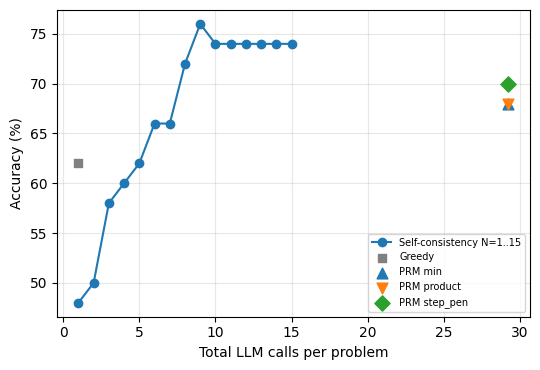

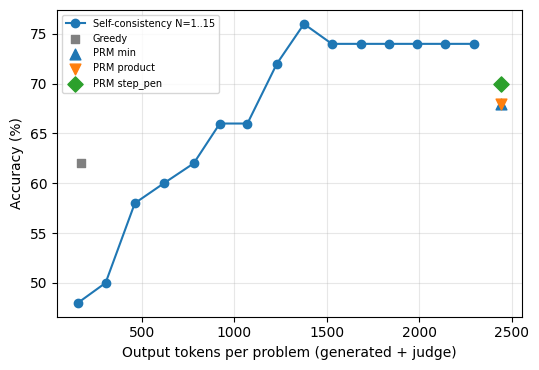

In [61]:
import matplotlib.pyplot as plt

# per-problem averages
sc_calls = [c["N"] for c in curve]                         
sc_toks  = [c["Avg Gen Tokens / Problem"] for c in curve]
sc_acc   = [c["Accuracy (%)"] for c in curve]

prm_calls = 5 + sum(jc) / 50                               
prm_toks  = float(np.mean(sc5_t)) + float(np.mean(jt))     
greedy_tok = float(np.mean([r["greedy"]["generated_tokens"] for r in R]))
acc = {s["Method"]: s["Accuracy (%)"] for s in summary}
prm_pts = [("PRM min", acc["PRM Best-of-5 (min)"]),
           ("PRM product", acc["PRM Best-of-5 (product)"]),
           ("PRM step_pen", acc["PRM Best-of-5 (step_penalty, lambda=2.0)"])]

for fname, xs, xlab, px, gx in [
    ("outputs/scaling_calls.png", sc_calls, "Total LLM calls per problem", prm_calls, 1),
    ("outputs/scaling_tokens.png", sc_toks, "Output tokens per problem (generated + judge)", prm_toks, greedy_tok)]:
    plt.figure(figsize=(5.5, 3.8))
    plt.plot(xs, sc_acc, "o-", label="Self-consistency N=1..15")
    plt.scatter([gx], [acc["Greedy (N=1)"]], marker="s", c="gray", zorder=3, label="Greedy")
    for (name, a), m in zip(prm_pts, ["^", "v", "D"]):
        plt.scatter([px], [a], marker=m, s=60, zorder=3, label=name)
    plt.xlabel(xlab); plt.ylabel("Accuracy (%)"); plt.grid(alpha=.3)
    plt.legend(fontsize=7); plt.tight_layout(); plt.savefig(fname, dpi=200); plt.show()

In [75]:
import json
import random

qs = {}

for line in open("data/gsm8k_test_50.jsonl"):
    data = json.loads(line)
    qs[data["id"]] = data["question"]

pool = []

for r, g in zip(R, gt):
    for ci, c in enumerate(r["scored_candidates5"]):
        for si, score in enumerate(c["step_scores"]):
            judge = "VALID" if score > 0 else "INVALID"

            pool.append({
                "id": r["id"],
                "cand": ci,
                "step_idx": si,
                "judge": judge,
                "rationale": c["rationales"][si],
                "step": c["steps"][si],
                "preceding": c["steps"][:si],
                "path_correct": c["answer"] == g
            })

inv = []
v_bad = []
v_ok = []

for x in pool:
    if x["judge"] == "INVALID":
        inv.append(x)
    elif x["path_correct"]:
        v_ok.append(x)
    else:
        v_bad.append(x)

random.seed(5326)

sample = []

for group, count in [(inv, 15), (v_bad, 8), (v_ok, 7)]:
    sample.extend(random.sample(group, min(count, len(group))))

random.shuffle(sample)

for i, x in enumerate(sample):
    x["audit_id"] = i

with open("outputs/judge_audit_sample.json", "w") as f:
    json.dump(sample, f, indent=2)
    

for x in sample:
    print(f"\n-----------\n\n #{x['audit_id']}  ({x['id']}, cand {x['cand']}, step {x['step_idx'] + 1})")
    print("q:", qs[x["id"]])

    for j, step in enumerate(x["preceding"], 1):
        print(f"  step {j}: {step}")

    print("current step:", x["step"])


-----------

 #0  (gsm8k_test_47, cand 1, step 4)
q: Candice put 80 post-it notes in her purse before she headed out to her job at the coffee shop.  On her way, she stopped off at the store and purchased a package of Post-it notes;  At work, she placed a single Post-it note on each of 220 different cups of coffee.  If she had 23 post-it notes remaining overall, how many Post-it notes were in the package that she purchased?
  step 1: Candice initially had 80 post-it notes.
  step 2: She placed 220 post-it notes on the coffee cups.
  step 3: She had 23 post-it notes remaining overall. 
(80 - 220) + 23 = -97
This calculation seems incorrect because it results in a negative number of notes, which is not possible. Let's re-evaluate the problem.
current step: Correct calculation:
(80 - 220) - 23 = -163

This still doesn't make sense because we can't have a negative number of post-it notes. Let's try a different approach.

-----------

 #1  (gsm8k_test_30, cand 3, step 1)
q: Gloria is shoe s

In [77]:
labels = {
    0:"INVALID",
    1:"VALID",
    2:"VALID",
    3:"VALID",
    4:"VALID",
    5:"VALID",
    6:"VALID",
    7:"INVALID",
    8:"VALID",
    9:"INVALID",
    10:"VALID",
    11:"VALID",
    12:"VALID",
    13:"INVALID",
    14:"VALID",
    15:"VALID",
    16:"VALID",
    17:"VALID",
    18:"INVALID",
    19:"VALID",
    20:"VALID",
    21:"VALID",
    22:"VALID",
    23:"VALID",
    24:"VALID",
    25:"VALID",
    26:"VALID",
    27:"VALID",
    28:"VALID",
    29:"VALID",
}
assert len(labels) == len(sample), f"label all {len(sample)} steps"

In [85]:
json.dump(labels, open("outputs/audit_labels.json", "w"))
print(len(labels), "labels saved")

30 labels saved


In [80]:
!pytest -v tests/test_public_adapter_smoke.py

============================= test session starts ==============================
platform linux -- Python 3.13.16, pytest-8.4.2, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /kaggle/working/repo
configfile: pyproject.toml
plugins: anyio-4.15.1, langsmith-0.14.12, platformdirs-4.13.5, typeguard-4.6.0
collected 20 items                                                             

tests/test_public_adapter_smoke.py::test_format_step_prompt PASSED       [  5%]
tests/test_public_adapter_smoke.py::test_parse_steps_plain PASSED        [ 10%]
tests/test_public_adapter_smoke.py::test_parse_steps_markdown_decorated PASSED [ 15%]
tests/test_public_adapter_smoke.py::test_extract_answer_required_behaviors PASSED [ 20%]
tests/test_public_adapter_smoke.py::test_extract_answer_resilience PASSED [ 25%]
tests/test_public_adapter_smoke.py::test_compute_majority_vote PASSED    [ 30%]
tests/test_public_adapter_smoke.py::test_run_greedy PASSED               [ 35%]
tests/test_public_ada

# for the report 

In [83]:
greedy_tot = float(np.mean([r["greedy"]["generated_tokens"] for r in R]))
budget = 10 * greedy_tot
fit = [c for c in curve if c["Avg Gen Tokens / Problem"] <= budget]
best = max(fit, key=lambda c: c["N"])
prm_total = float(np.mean(sc5_t)) + float(np.mean(jt))
print(f"greedy tokens/problem: {greedy_tot:.1f} -> 10x budget: {budget:.1f}")
print(f"SC within budget: N={best['N']}, acc={best['Accuracy (%)']}%, tokens={best['Avg Gen Tokens / Problem']}")
print(f"PRM Best-of-5: gen {np.mean(sc5_t):.1f} + judge {np.mean(jt):.1f} = {prm_total:.1f} tokens "
      f"({prm_total/budget:.2f}x budget), acc min/prod/pen = "
      f"{acc_by['PRM Best-of-5 (min)']}/{acc_by['PRM Best-of-5 (product)']}/"
      f"{acc_by['PRM Best-of-5 (step_penalty, lambda=2.0)']}")
print(f"per problem: {5} gen calls vs {J/50:.1f} judge calls | "
      f"tokens/call: judge {sum(jt)/J:.1f}, generator {np.mean(sc5_t)/5:.1f}")

greedy tokens/problem: 173.3 -> 10x budget: 1733.2
SC within budget: N=11, acc=74.0%, tokens=1685.16
PRM Best-of-5: gen 781.2 + judge 1659.5 = 2440.7 tokens (1.41x budget), acc min/prod/pen = 68.0/68.0/70.0
per problem: 5 gen calls vs 24.2 judge calls | tokens/call: judge 68.5, generator 156.2


In [86]:
import json
sample = json.load(open("outputs/judge_audit_sample.json"))
labels = {int(k): v for k, v in json.load(open("outputs/audit_labels.json")).items()}
assert len(labels) == len(sample)
TP = FP = TN = FN = 0
for x in sample:
    truth, j = labels[x["audit_id"]], x["judge"]
    TP += (j == "INVALID" and truth == "INVALID")
    FP += (j == "INVALID" and truth == "VALID")
    TN += (j == "VALID"   and truth == "VALID")
    FN += (j == "VALID"   and truth == "INVALID")
print(dict(TP=TP, FP=FP, TN=TN, FN=FN))
print("INVALID precision:", round(TP/(TP+FP), 3) if TP+FP else None)
print("INVALID recall   :", round(TP/(TP+FN), 3) if TP+FN else None)
for x in sample:                                   # report wording (Section 7.3)
    if labels[x["audit_id"]] != x["judge"]:
        kind = ("JUDGE FALSE NEGATIVE (valid step marked INVALID)" if x["judge"] == "INVALID"
                else "JUDGE FALSE POSITIVE (flawed step marked VALID)")
        print(f"\n#{x['audit_id']} {x['id']} cand {x['cand']} step {x['step_idx']+1}: {kind}")
        print("  step:", x["step"]); print("  judge:", x["rationale"])

{'TP': 5, 'FP': 10, 'TN': 15, 'FN': 0}
INVALID precision: 0.333
INVALID recall   : 1.0

#4 gsm8k_test_17 cand 2 step 3: JUDGE FALSE NEGATIVE (valid step marked INVALID)
  step: The second train covers a total of 80 + 150 = 230 miles.
  judge: The calculation assumes that the second train also traveled 80 miles west and 150 miles north, which is not stated in the problem.

#6 gsm8k_test_37 cand 4 step 2: JUDGE FALSE NEGATIVE (valid step marked INVALID)
  step: They are currently on sale at 4 yogurts for $5.00.
5 / 4 = 1.25
  judge: The current step attempts to calculate the cost per yogurt, but it does not follow logically from the previous steps provided.

#19 gsm8k_test_21 cand 4 step 5: JUDGE FALSE NEGATIVE (valid step marked INVALID)
  step: 6 + 9 = 15 liters of water in total.
  judge: The current step assumes that the 6 liters of water from the remaining orange drink and the 9 liters of water from the pineapple drink are being added together, which is not logically derived from th

In [ ]:
# 1) Judge false-positive candidates: PRM picked a wrong answer from a fully-VALID path
print("== PRM chose a wrong answer on an all-VALID path ==")
for r, g, b in zip(R, gt, sel["min"]):
    if b["answer"] != g and b["path_score"] == 1.0:
        print(r["id"], "| chose", b["answer"], "| gt", g)

# 2) Judge false-negative candidates: correct path that has an INVALID step
print("\n== Correct-answer paths with an INVALID step ==")
for r, g in zip(R, gt):
    for ci, c in enumerate(r["scored_candidates5"]):
        if c["answer"] == g and -1.0 in c["step_scores"]:
            si = c["step_scores"].index(-1.0)
            print(r["id"], "cand", ci, "step", si+1, "|", c["rationales"][si][:100])


from collections import Counter
print("\n== Shared wrong answer across samples ==")
for r, g in zip(R, gt):
    cnt = Counter(c["answer"] for c in r["candidates15"] if c["answer"] is not None)
    if cnt:
        a, n = cnt.most_common(1)[0]
        if a != g and n >= 12:
            print(r["id"], "| wrong answer", a, f"in {n}/15 | gt", g)

== PRM chose a wrong answer on an all-VALID path ==
gsm8k_test_16 | chose 221 | gt 125
gsm8k_test_18 | chose 145000 | gt 57500
gsm8k_test_40 | chose 12 | gt 18
gsm8k_test_44 | chose 8 | gt 48

== Correct-answer paths with an INVALID step ==
gsm8k_test_01 cand 0 step 3 | The current step contradicts the information provided in Step 2, which states that Janet eats 3 eggs
gsm8k_test_01 cand 3 step 4 | The current step introduces new information about baking muffins for her friends with 4 eggs, which 
gsm8k_test_03 cand 3 step 3 | The statement that the value of the house increased by 150% and thus became 250% of its original val
gsm8k_test_04 cand 2 step 5 | The current step incorrectly calculates the meters per sprint instead of the total meters per sessio
gsm8k_test_04 cand 3 step 3 | The current step incorrectly multiplies the number of sprints per week by itself, which is not logic
gsm8k_test_04 cand 4 step 1 | The current step is not directly supported by the problem statement.
gsm8k

In [89]:
import torch, transformers, platform
print("python", platform.python_version(), "| torch", torch.__version__,
      "| transformers", transformers.__version__)
try:
    import bitsandbytes as bnb; print("bitsandbytes", bnb.__version__)
except Exception as e: print("bitsandbytes n/a", e)
print("GPUs:", [torch.cuda.get_device_name(i) for i in range(torch.cuda.device_count())])
tot = sum(r["greedy"]["time_seconds"] + r["sc5"]["time_seconds"] + r["prm"]["time_seconds"]
          + r["sc15"]["time_seconds"] for r in R)
print(f"total measured compute time: {tot/3600:.2f} h")

python 3.13.16 | torch 2.11.0+cu130 | transformers 5.20.2
bitsandbytes 0.50.2
GPUs: ['Tesla T4', 'Tesla T4']
total measured compute time: 2.13 h
